# Do Hidden Market Regimes Improve Tail-Risk Forecasts?

This notebook is an executable tour. It distinguishes predicted, filtered and smoothed states, fits only on a training segment, and reads the complete research audit. The package implements inference itself; `hmmlearn` is only an independent test oracle.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'src'))
from regime_risk.hmm import HiddenMarkovModel
from regime_risk.data import simulate_regimes
from regime_risk.evaluation import coverage_tests, quantile_loss
print('Imports ready; all examples use explicit random seeds.')

Imports ready; all examples use explicit random seeds.


## 1. Fit a heavy-tailed regime model

The synthetic path has known states. Only the first 1,000 observations estimate parameters. State 1 means higher emission variance, not a factual economic label.

In [2]:
returns, states = simulate_regimes(1400, seed=1729, kind='student')
train, test = returns[:1000], returns[1000:]
scale = train.std()
model = HiddenMarkovModel(emission='student', n_init=4, random_state=1729).fit(train / scale)
print('Converged:', model.converged_, '| selected iterations:', model.n_iter_)
print('Transition matrix:')
print(np.round(model.params.transition, 3))
print('Emission standard deviations:', np.round(np.sqrt(model.variances) * scale, 5))

Converged: True | selected iterations: 13
Transition matrix:
[[0.985 0.015]
 [0.066 0.934]]
Emission standard deviations: [0.00618 0.01783]


## 2. Issue forecasts before the outcome

The last training posterior is advanced through the transition matrix before the first test observation. Quantiles come from the predictive mixture; a weighted mean of component quantiles would be incorrect.

In [3]:
last_train = model.filter(train / scale)[0][-1]
filtered, predicted, log_scores = model.filter(test / scale, last_train @ model.params.transition)
q05 = scale * model.mixture_quantile(.05, predicted)
diagnostics = coverage_tests(test, q05, .05)
print('Mean held-out log density:', round(float(np.mean(log_scores - np.log(scale))), 4))
print('5% breach rate:', round(diagnostics['breach_rate'], 4))
print('Pinball loss:', round(float(quantile_loss(test, q05, .05).mean()), 6))
assert np.allclose(predicted.sum(axis=1), 1)

Mean held-out log density: 3.2278
5% breach rate: 0.0625
Pinball loss: 0.00132


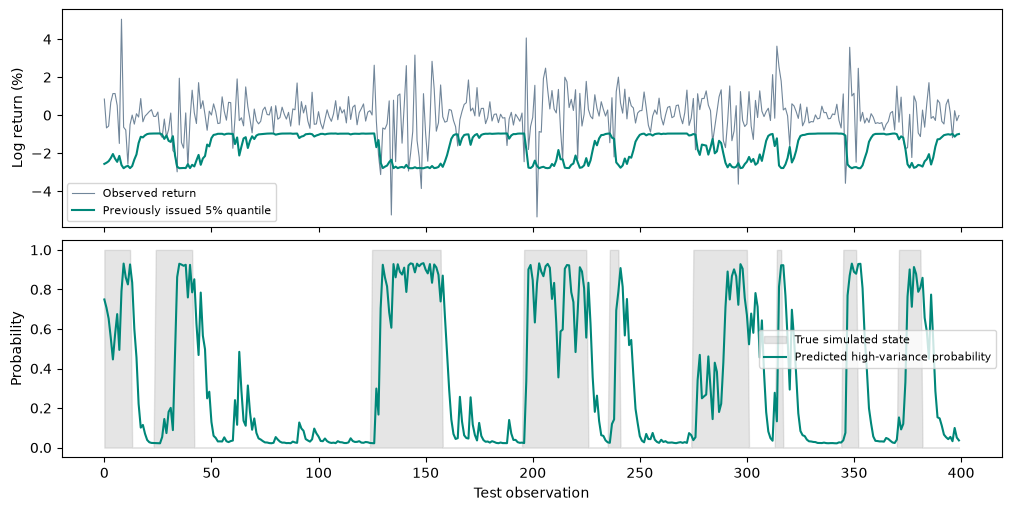

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, constrained_layout=True)
axes[0].plot(test * 100, color='#71869a', lw=.8, label='Observed return')
axes[0].plot(q05 * 100, color='#008779', label='Previously issued 5% quantile')
axes[0].set_ylabel('Log return (%)'); axes[0].legend(fontsize=8)
axes[1].fill_between(np.arange(len(test)), states[1000:], alpha=.2, color='gray', label='True simulated state')
axes[1].plot(predicted[:, 1], color='#008779', label='Predicted high-variance probability')
axes[1].set_ylabel('Probability'); axes[1].set_xlabel('Test observation'); axes[1].legend(fontsize=8)
plt.show()

## 3. A direct test for future leakage

Change later observations dramatically. Earlier causal forecasts must remain unchanged; offline smoothed probabilities are allowed to change because they deliberately use future information.

In [5]:
changed = test.copy(); changed[200:] += .2
changed_post, changed_pred, _ = model.filter(changed / scale, last_train @ model.params.transition)
assert np.allclose(predicted[:201], changed_pred[:201])
assert np.allclose(filtered[:200], changed_post[:200])
print('Passed: future outcomes cannot alter already-issued predictions.')

Passed: future outcomes cannot alter already-issued predictions.


## 4. Inspect every model, including stronger baselines

The committed real-data experiment evaluates three currency series. A follow-up Student-t EWMA control is explicitly labeled in the research log. These noon rates do not support an execution or live-trading claim.

In [6]:
summary = pd.read_csv(root / 'results/full/real_summary.csv')
display(summary[['asset', 'model', 'mean_log_score', 'breach_rate', 'adaptive_breach_rate']].round(4))

,asset,model,mean_log_score,breach_rate,adaptive_breach_rate
0,EURUSD,gaussian_iid,3.7593,0.0469,0.0496
1,EURUSD,student_iid,3.8082,0.0509,0.0501
2,EURUSD,gaussian_hmm,3.8181,0.0541,0.0501
3,EURUSD,student_hmm,3.8351,0.0511,0.0499
4,EURUSD,rolling_gaussian,3.8081,0.0534,0.0490
5,EURUSD,ewma_gaussian,3.8506,0.0564,0.0496
6,EURUSD,ewma_student,3.8645,0.0640,0.0503
7,GBPUSD,gaussian_iid,3.6461,0.0477,0.0478
8,GBPUSD,student_iid,3.7526,0.0551,0.0486
9,GBPUSD,gaussian_hmm,3.7355,0.0499,0.0486


In [7]:
comparisons = pd.read_csv(root / 'results/full/paired_logscore_intervals.csv')
display(comparisons[['asset', 'comparison', 'mean', 'lower', 'upper']].round(4))
import json
audit = json.loads((root / 'results/full/fit_audit.json').read_text())
assert all(fit['train_end_exclusive'] == fit['test_start'] for fit in audit)
print('Audited chronological fit boundaries:', len(audit))

,asset,comparison,mean,lower,upper
0,EURUSD,student_hmm minus gaussian_hmm,0.0170,0.0051,0.0306
1,EURUSD,student_hmm minus student_iid,0.0269,0.0172,0.0362
2,EURUSD,student_hmm minus ewma_gaussian,-0.0154,-0.0328,0.0018
3,EURUSD,gaussian_hmm minus gaussian_iid,0.0588,0.0428,0.0753
4,EURUSD,student_hmm minus ewma_student,-0.0294,-0.0405,-0.0195
5,GBPUSD,student_hmm minus gaussian_hmm,0.0486,0.0052,0.1178
6,GBPUSD,student_hmm minus student_iid,0.0314,0.0182,0.0458
7,GBPUSD,student_hmm minus ewma_gaussian,-0.0112,-0.0243,0.0039
8,GBPUSD,gaussian_hmm minus gaussian_iid,0.0894,0.0595,0.1245
9,GBPUSD,student_hmm minus ewma_student,-0.0223,-0.0324,-0.0123


Audited chronological fit boundaries: 252


## 5. Interpret a failure

Under a persistent scale break, all fitted model families can under-cover the lower tail. Better average log score does not promise a correct 5% risk threshold. The online controller is a practical adjustment, not a new finite-sample coverage theorem.

In [8]:
synthetic = pd.read_csv(root / 'results/full/synthetic_summary.csv')
display(synthetic[synthetic.dgp == 'break'][['model', 'mean_log_score', 'breach_rate', 'adaptive_breach_rate']].round(4))

,model,mean_log_score,breach_rate,adaptive_breach_rate
0,gaussian_hmm,2.6146,0.0874,0.0778
1,gaussian_iid,2.0328,0.1041,0.0906
2,student_hmm,2.6785,0.0810,0.0723
3,student_iid,2.4585,0.1334,0.1090


For derivations, assumptions, data provenance, and reproduction commands, see the repository README and `docs/`. A quantitative explanation should include the cases where a simple benchmark wins, not just the best-looking model output.